In [1]:
!pip install -q umap-learn kneed

In [2]:
import os, time, glob, zipfile, shutil, warnings, tracemalloc, urllib.request
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.datasets import fetch_openml, make_blobs, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score)
import umap
from kneed import KneeLocator

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | umap {umap.__version__}")

numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | umap 0.5.12


In [3]:
# ======================= EXPERIMENT CONFIGURATION =======================
SEED           = 42
N_SAMPLES      = 3000      # stratified samples per dataset (None = full data -> not feasible with exact t-SNE)
N_RUNS         = 10        # runs per (dataset, representation, algorithm)   [paper: 10]
N_STABILITY    = 100       # runs per configuration in the stability study   [paper: 100]
DR_DIM         = 50        # dimensionality used for clustering             [paper: 50]
TSNE_MODE      = 'exact'   # 'exact' = 50-D t-SNE (paper, slow) | 'fast' = 3-D Barnes-Hut t-SNE
KMEANS_N_INIT  = 10        # k-means++ restarts                              [paper: 10]
MIN_PTS        = 10        # DBSCAN minPts                                   [paper: 10]
SPEC_NEIGHBORS = 10        # Spectral nearest-neighbour graph                [paper: 10]

ALGOS   = ['K-means', 'DBSCAN', 'Spectral']
REPS    = ['Raw', 'PCA', 't-SNE', 'UMAP']
PALETTE = {'K-means': '#1f77b4', 'DBSCAN': '#ff7f0e', 'Spectral': '#2ca02c'}

USE_DRIVE = False
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/clustering_replication'
else:
    OUT_DIR = '/content/clustering_replication'

FIG_DIR, TAB_DIR, CACHE_DIR = [os.path.join(OUT_DIR, s) for s in ('figures', 'tables', 'cache')]
for p in (FIG_DIR, TAB_DIR, CACHE_DIR):
    os.makedirs(p, exist_ok=True)
np.random.seed(SEED)
print("Results will be saved in:", OUT_DIR)

Results will be saved in: /content/clustering_replication


In [4]:
def save_table(df, name):
    df.to_csv(os.path.join(TAB_DIR, f'{name}.csv'), index=False)
    try:
        with open(os.path.join(TAB_DIR, f'{name}.tex'), 'w') as f:
            f.write(df.to_latex(index=False))
    except Exception as e:
        print('  (LaTeX export skipped:', e, ')')

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=300, bbox_inches='tight')
    fig.savefig(os.path.join(FIG_DIR, f'{name}.pdf'), bbox_inches='tight')

def pm(values, d=3):
    """Format as 'mean ± std' (population std, like np.std)."""
    s = pd.Series(values).dropna()
    return 'n/a' if len(s) == 0 else f"{s.mean():.{d}f} ± {s.std(ddof=0):.{d}f}"

def plot_labels(ax, Z, labels, title, s=3):
    """Scatter 2-D points coloured by cluster; label -1 (noise) in light grey."""
    labels = np.asarray(labels)
    clusters = [c for c in np.unique(labels) if c != -1]
    cmap = plt.get_cmap('tab10' if len(clusters) <= 10 else 'tab20')
    for i, c in enumerate(clusters):
        m = labels == c
        ax.scatter(Z[m, 0], Z[m, 1], s=s, color=cmap(i % cmap.N), alpha=0.8, linewidths=0)
    noise = labels == -1
    if noise.any():
        ax.scatter(Z[noise, 0], Z[noise, 1], s=s, color='lightgrey', alpha=0.6, linewidths=0)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

def stratified_subsample(X, y, n, seed=SEED):
    """Keep class proportions identical to the full dataset."""
    if n is None or n >= len(X):
        return X, y
    Xs, _, ys, _ = train_test_split(X, y, train_size=n, stratify=y, random_state=seed)
    return Xs, ys

In [5]:
# ---------- MNIST via Keras only (fast, reliable) ----------
from tensorflow.keras.datasets import mnist as keras_mnist

print("Loading MNIST from Keras ...")
(Xtr, ytr), (Xte, yte) = keras_mnist.load_data()
X_mnist_full = np.vstack([Xtr, Xte]).reshape(-1, 784).astype(np.float32)
y_mnist_full = np.hstack([ytr, yte]).astype(int)

# Same downstream processing as before (unchanged)
X_mnist, y_mnist = stratified_subsample(X_mnist_full, y_mnist_full, N_SAMPLES)

print(f"Full MNIST : {X_mnist_full.shape}")
print(f"Used       : {X_mnist.shape} | class counts: {np.bincount(y_mnist)}")

Loading MNIST from Keras ...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Full MNIST : (70000, 784)
Used       : (3000, 784) | class counts: [296 338 300 306 292 270 295 313 292 298]


In [6]:
HAR_URLS = [
    'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip',
    'https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip',
]

def find_har_root(dest):
    hits = [h for h in glob.glob(f'{dest}/**/X_train.txt', recursive=True) if '__MACOSX' not in h]
    return os.path.dirname(os.path.dirname(hits[0])) if hits else None

def extract_all_zips(dest):
    for zp in glob.glob(f'{dest}/**/*.zip', recursive=True):
        if '__MACOSX' in zp or os.path.basename(zp).startswith('._'):
            continue
        try:
            with zipfile.ZipFile(zp) as z:
                z.extractall(os.path.dirname(zp))
        except zipfile.BadZipFile:
            pass

def get_har(dest='/content/har_data'):
    os.makedirs(dest, exist_ok=True)
    extract_all_zips(dest)                      # handles a manually uploaded zip
    root = find_har_root(dest)
    if root: return root
    for url in HAR_URLS:
        try:
            print("Downloading", url)
            urllib.request.urlretrieve(url, os.path.join(dest, 'har_download.zip'))
            extract_all_zips(dest); extract_all_zips(dest)   # twice for the nested zip
            root = find_har_root(dest)
            if root: return root
        except Exception as e:
            print("  failed:", e)
    raise RuntimeError("UCI HAR download failed - upload the zip manually to /content/har_data/")

def read_txt(path):
    return pd.read_csv(path, sep=r'\s+', header=None).values

har_root = get_har()
X_har_full = np.vstack([read_txt(f'{har_root}/train/X_train.txt'),
                        read_txt(f'{har_root}/test/X_test.txt')]).astype(np.float32)
y_har_full = np.concatenate([read_txt(f'{har_root}/train/y_train.txt').ravel(),
                             read_txt(f'{har_root}/test/y_test.txt').ravel()]).astype(int)
har_names = dict(read_txt(f'{har_root}/activity_labels.txt').tolist())
X_har, y_har = stratified_subsample(X_har_full, y_har_full, N_SAMPLES)

print(f"Full HAR : {X_har_full.shape}")
print(f"Used     : {X_har.shape}")
print("Activities:", har_names)

Full HAR : (10299, 561)
Used     : (3000, 561)
Activities: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}


,Dataset,Original samples,Samples used,Features,Clusters (k)
0,MNIST,70000,3000,784,10
1,UCI HAR,10299,3000,561,6


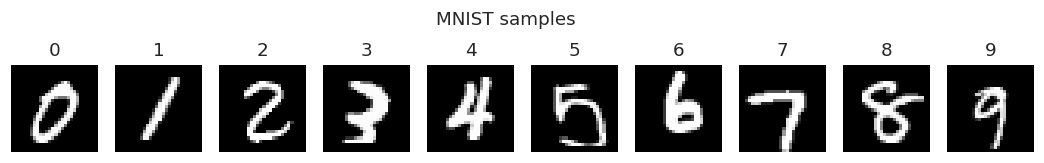

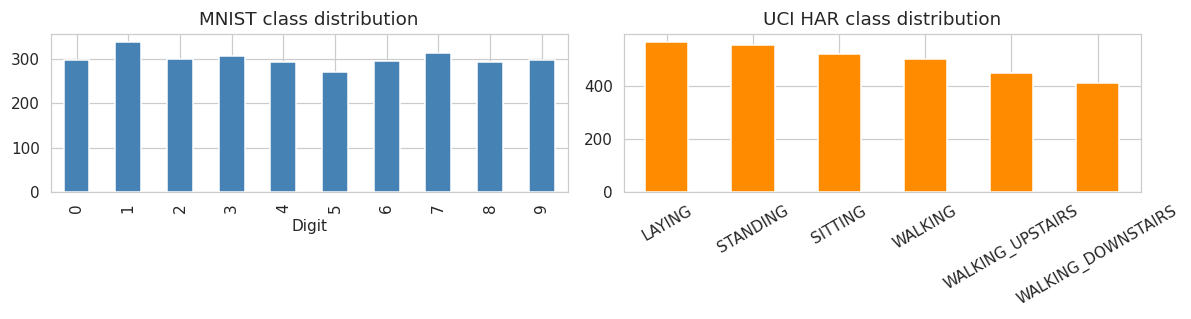

In [7]:
DATASETS = {
    'MNIST':   {'X': X_mnist, 'y': y_mnist, 'k': 10, 'n_full': len(X_mnist_full)},
    'UCI HAR': {'X': X_har,   'y': y_har,   'k': 6,  'n_full': len(X_har_full)},
}

summary = pd.DataFrame([{'Dataset': n, 'Original samples': d['n_full'], 'Samples used': len(d['X']),
                         'Features': d['X'].shape[1], 'Clusters (k)': d['k']}
                        for n, d in DATASETS.items()])
display(summary)
save_table(summary, 'dataset_summary')

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for digit, ax in enumerate(axes):
    ax.imshow(X_mnist[y_mnist == digit][0].reshape(28, 28), cmap='gray')
    ax.set_title(str(digit)); ax.axis('off')
plt.suptitle('MNIST samples', y=1.05); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
pd.Series(y_mnist).value_counts().sort_index().plot.bar(ax=axes[0], color='steelblue')
axes[0].set_title('MNIST class distribution'); axes[0].set_xlabel('Digit')
pd.Series([har_names[v] for v in y_har]).value_counts().plot.bar(ax=axes[1], color='darkorange')
axes[1].set_title('UCI HAR class distribution'); axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); save_fig(fig, 'fig0_class_distribution'); plt.show()

In [8]:
for name, d in DATASETS.items():
    d['X_std'] = StandardScaler().fit_transform(d['X']).astype(np.float32)
    nonconst = d['X'].std(axis=0) > 0
    print(f"{name:8s} | shape {d['X_std'].shape} | global mean {d['X_std'].mean():+.4f} | "
          f"mean std (non-constant features) {d['X_std'][:, nonconst].std(axis=0).mean():.4f} | "
          f"constant features: {(~nonconst).sum()}")

MNIST    | shape (3000, 784) | global mean -0.0000 | mean std (non-constant features) 1.0000 | constant features: 143
UCI HAR  | shape (3000, 561) | global mean -0.0000 | mean std (non-constant features) 1.0000 | constant features: 0


In [9]:
def cached_embedding(ds_name, key, fn):
    path = os.path.join(CACHE_DIR, f"{ds_name.replace(' ', '_')}_{key}_n{N_SAMPLES}_s{SEED}.npz")
    if os.path.exists(path):
        z = np.load(path)
        print(f"   [cache] {key:9s} {z['Z'].shape}")
        return z['Z'], float(z['t'])
    t0 = time.perf_counter()
    Z = np.asarray(fn(), dtype=np.float32)
    t = time.perf_counter() - t0
    np.savez(path, Z=Z, t=t)
    print(f"   {key:9s} {Z.shape}  computed in {t:7.1f}s")
    return Z, t

def make_tsne():
    if TSNE_MODE == 'exact':
        return TSNE(n_components=DR_DIM, method='exact', perplexity=30, init='pca',
                    learning_rate='auto', random_state=SEED, verbose=1), f'TSNE{DR_DIM}'
    return TSNE(n_components=3, method='barnes_hut', perplexity=30, init='pca',
                learning_rate='auto', random_state=SEED), 'TSNE3'

dr_rows = []
for name, d in DATASETS.items():
    print(f"\n=== {name} ===")
    X = d['X_std']
    reps = {'Raw': X}
    reps['PCA'],   t_pca  = cached_embedding(name, f'PCA{DR_DIM}',
                               lambda: PCA(n_components=DR_DIM, random_state=SEED).fit_transform(X))
    tsne, key = make_tsne()
    reps['t-SNE'], t_tsne = cached_embedding(name, key, lambda: tsne.fit_transform(X))
    reps['UMAP'],  t_umap = cached_embedding(name, f'UMAP{DR_DIM}',
                               lambda: umap.UMAP(n_components=DR_DIM, random_state=SEED).fit_transform(X))
    d['vis2d'], _         = cached_embedding(name, 'UMAP2',
                               lambda: umap.UMAP(n_components=2, random_state=SEED).fit_transform(X))
    d['reps'] = reps
    evr = PCA(n_components=DR_DIM, random_state=SEED).fit(X).explained_variance_ratio_.sum()
    dr_rows.append({'Dataset': name, 'PCA time (s)': round(t_pca, 2), 't-SNE time (s)': round(t_tsne, 2),
                    'UMAP time (s)': round(t_umap, 2), f'PCA-{DR_DIM} variance retained': round(evr, 3)})

dr_table = pd.DataFrame(dr_rows)
display(dr_table)
save_table(dr_table, 'table_dr_times')


=== MNIST ===
   PCA50     (3000, 50)  computed in     1.1s
[t-SNE] Computing pairwise distances...
[t-SNE] Computed conditional probabilities for sample 1000 / 3000
[t-SNE] Computed conditional probabilities for sample 2000 / 3000
[t-SNE] Computed conditional probabilities for sample 3000 / 3000
[t-SNE] Mean sigma: 6.086207
[t-SNE] KL divergence after 250 iterations with early exaggeration: 80.690116
[t-SNE] KL divergence after 700 iterations: 3.149280
   TSNE50    (3000, 50)  computed in   851.5s
   UMAP50    (3000, 50)  computed in    33.5s
   UMAP2     (3000, 2)  computed in    18.3s

=== UCI HAR ===
   PCA50     (3000, 50)  computed in     0.9s
[t-SNE] Computing pairwise distances...
[t-SNE] Computed conditional probabilities for sample 1000 / 3000
[t-SNE] Computed conditional probabilities for sample 2000 / 3000
[t-SNE] Computed conditional probabilities for sample 3000 / 3000
[t-SNE] Mean sigma: 4.347242
[t-SNE] KL divergence after 250 iterations with early exaggeration: 72.031

,Dataset,PCA time (s),t-SNE time (s),UMAP time (s),PCA-50 variance retained
0,MNIST,1.14,851.48,33.48,0.631
1,UCI HAR,0.90,767.35,23.03,0.875


MNIST    | Raw    | eps= 19.9943 (FALLBACK-closest-k) | clusters=  2 | noise= 29.3% | knee eps= 43.8723
MNIST    | PCA    | eps= 13.0096 (FALLBACK-closest-k) | clusters=  3 | noise= 25.2% | knee eps= 33.8864
MNIST    | t-SNE  | eps=  4.6731 (FALLBACK-closest-k) | clusters=  9 | noise=  8.0% | knee eps=  5.4018
MNIST    | UMAP   | eps=  0.5185 (silhouette        ) | clusters=  5 | noise=  1.2% | knee eps=  0.5899
UCI HAR  | Raw    | eps= 14.7267 (FALLBACK-closest-k) | clusters=  6 | noise= 32.7% | knee eps= 28.4797
UCI HAR  | PCA    | eps= 11.3371 (FALLBACK-closest-k) | clusters=  6 | noise= 30.4% | knee eps= 28.9575
UCI HAR  | t-SNE  | eps=  4.5834 (FALLBACK-closest-k) | clusters=  4 | noise=  3.9% | knee eps=  5.2389
UCI HAR  | UMAP   | eps=  0.5253 (FALLBACK-closest-k) | clusters= 10 | noise=  0.3% | knee eps=  0.4868


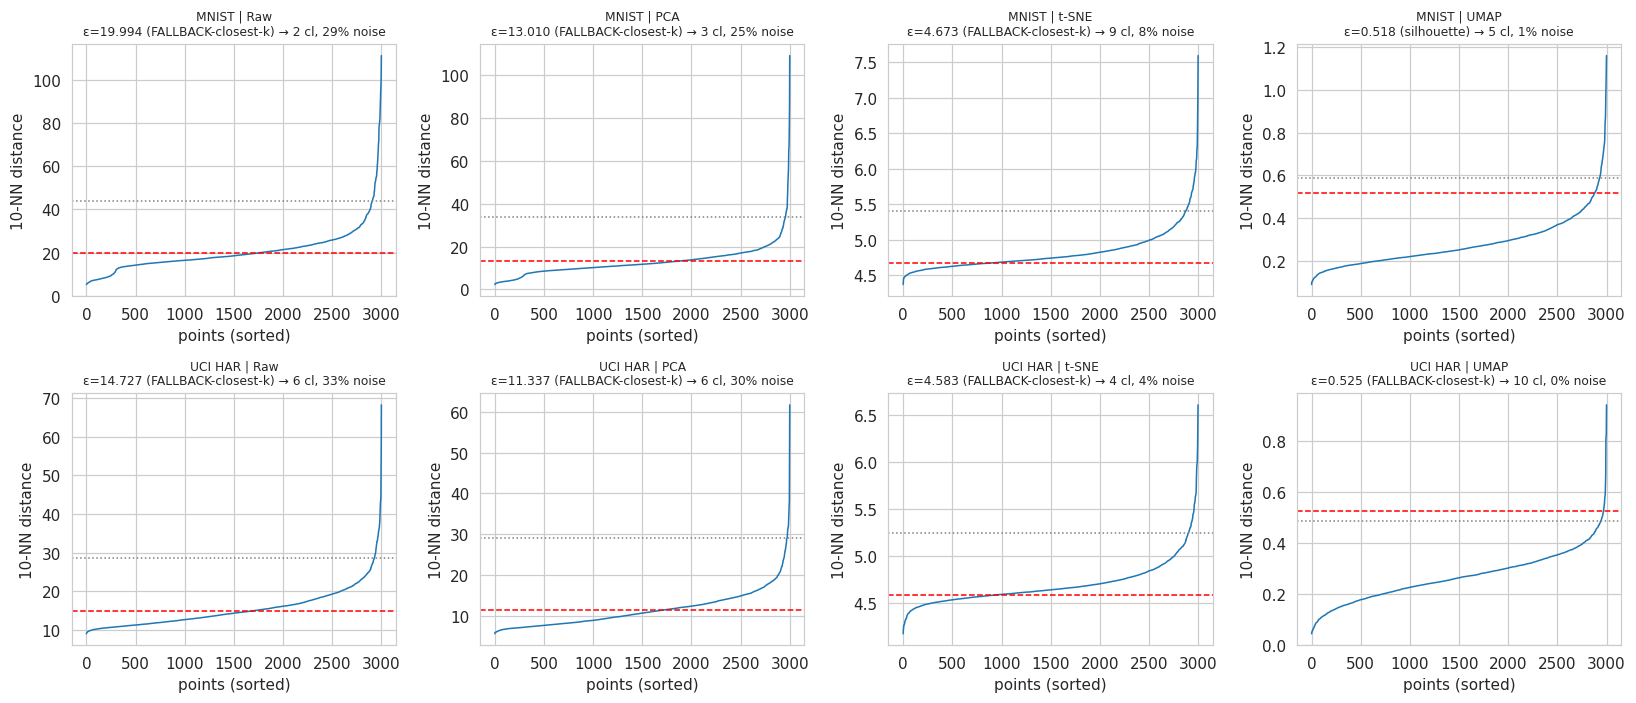

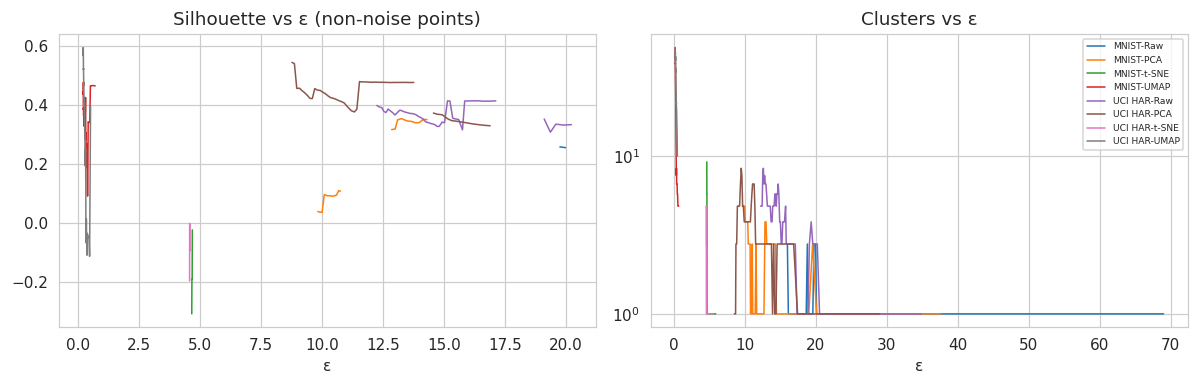

,Dataset,Representation,eps knee,eps selected,rule,ARI oracle max (report only)
0,MNIST,Raw,43.8723,19.9943,FALLBACK-closest-k,0.053
1,MNIST,PCA,33.8864,13.0096,FALLBACK-closest-k,0.065
2,MNIST,t-SNE,5.4018,4.6731,FALLBACK-closest-k,0.002
3,MNIST,UMAP,0.5899,0.5185,silhouette,0.624
4,UCI HAR,Raw,28.4797,14.7267,FALLBACK-closest-k,0.316
5,UCI HAR,PCA,28.9575,11.3371,FALLBACK-closest-k,0.319
6,UCI HAR,t-SNE,5.2389,4.5834,FALLBACK-closest-k,0.000
7,UCI HAR,UMAP,0.4868,0.5253,FALLBACK-closest-k,0.492


In [10]:
# ---------- Cell 10 (REPLACES old Cell 10): label-free DBSCAN eps selection ----------
EPS_OVERRIDE = {}     # manual override still possible, e.g. {('MNIST', 'Raw'): 28.0}
MAX_NOISE    = 0.20   # at most 20% of points may be labelled noise
MIN_CL_FRAC  = 0.01   # every cluster must contain at least 1% of the points

def k_distance(X, k=MIN_PTS):
    dist, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
    return np.sort(dist[:, -1])

def knee_eps(kd):
    kl = KneeLocator(np.arange(len(kd)), kd, curve='convex', direction='increasing')
    return float(kl.knee_y) if kl.knee_y is not None else float(np.percentile(kd, 90))

def dbscan_sweep(X, y, quantiles=np.arange(0.30, 0.996, 0.01)):
    """Try eps at many quantiles of the k-distance curve. y is logged for reporting only."""
    kd, n, rows = k_distance(X), len(X), []
    for q in quantiles:
        eps = float(np.quantile(kd, q))
        lab = DBSCAN(eps=eps, min_samples=MIN_PTS, n_jobs=-1).fit_predict(X)
        mask = lab != -1
        cl_ids, counts = np.unique(lab[mask], return_counts=True)
        ncl = len(cl_ids)
        sil = (silhouette_score(X[mask], lab[mask])
               if (ncl >= 2 and mask.sum() > ncl) else np.nan)
        rows.append(dict(q=round(q, 2), eps=eps, clusters=ncl,
                         noise=1 - mask.mean(),
                         smallest_frac=(counts.min() / n) if ncl else 0.0,
                         silhouette=sil,
                         ARI_report_only=adjusted_rand_score(y, lab)))
    return pd.DataFrame(rows)

def select_eps(X, y, k_true):
    """Label-free eps choice. Ground truth is NOT used to pick eps.
    Allowed: between ceil(k/2) and 2k clusters, at most 20% noise,
    smallest cluster at least 1% of points. Among these, best silhouette.
    If nothing qualifies, a flagged fallback is used and reported."""
    sw = dbscan_sweep(X, y)
    lo = max(2, int(np.ceil(k_true / 2)))
    hi = 2 * k_true
    ok = sw[(sw.clusters >= lo) & (sw.clusters <= hi) &
            (sw.noise <= MAX_NOISE) &
            (sw.smallest_frac >= MIN_CL_FRAC)].dropna(subset=['silhouette'])
    if len(ok):
        return float(ok.loc[ok.silhouette.idxmax(), 'eps']), sw, 'silhouette'
    cand = sw[(sw.clusters >= 2) & (sw.noise <= 0.5)].copy()
    if len(cand):
        cand['gap'] = (cand.clusters - k_true).abs()
        row = cand.sort_values(['gap', 'noise']).iloc[0]
        return float(row['eps']), sw, 'FALLBACK-closest-k'
    return knee_eps(k_distance(X)), sw, 'FALLBACK-knee'

# ---- EPS selection loop: runs select_eps on every dataset x representation ----
EPS, EPS_KNEE, EPS_FLAG, sweeps = {}, {}, {}, {}
fig, axes = plt.subplots(len(DATASETS), len(REPS), figsize=(15, 6.5))
for i, (name, d) in enumerate(DATASETS.items()):
    for j, rep in enumerate(REPS):
        X = d['reps'][rep]
        kd = k_distance(X)
        eps_knee = knee_eps(kd)
        eps, sw, flag = select_eps(X, d['y'], d['k'])
        if (name, rep) in EPS_OVERRIDE:
            eps, flag = EPS_OVERRIDE[(name, rep)], 'manual'
        EPS[(name, rep)] = eps
        EPS_KNEE[(name, rep)] = eps_knee
        EPS_FLAG[(name, rep)] = flag
        sweeps[(name, rep)] = sw

        lab = DBSCAN(eps=eps, min_samples=MIN_PTS, n_jobs=-1).fit_predict(X)
        ncl, noise = len(set(lab) - {-1}), np.mean(lab == -1)
        ax = axes[i, j]
        ax.plot(kd, lw=1)
        ax.axhline(eps, color='red', ls='--', lw=1, label='selected')
        ax.axhline(eps_knee, color='grey', ls=':', lw=1, label='knee')
        ax.set_title(f'{name} | {rep}\nε={eps:.3f} ({flag}) → {ncl} cl, {noise:.0%} noise', fontsize=8)
        ax.set_xlabel('points (sorted)')
        ax.set_ylabel(f'{MIN_PTS}-NN distance')
        print(f"{name:8s} | {rep:6s} | eps={eps:8.4f} ({flag:18s}) | clusters={ncl:3d} | "
              f"noise={noise:6.1%} | knee eps={eps_knee:8.4f}")
plt.tight_layout()
save_fig(fig, 'figS1_kdistance')
plt.show()

# Sweep curves (supplementary figure)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for (name, rep), sw in sweeps.items():
    axes[0].plot(sw.eps, sw.silhouette, lw=1, label=f'{name}-{rep}')
    axes[1].plot(sw.eps, sw.clusters, lw=1, label=f'{name}-{rep}')
axes[0].set_title('Silhouette vs ε (non-noise points)'); axes[0].set_xlabel('ε')
axes[1].set_title('Clusters vs ε'); axes[1].set_xlabel('ε'); axes[1].set_yscale('symlog')
axes[1].legend(fontsize=6)
plt.tight_layout(); save_fig(fig, 'figS2_dbscan_sweep'); plt.show()

sweep_all = pd.concat([sw.assign(Dataset=n, Representation=r) for (n, r), sw in sweeps.items()],
                      ignore_index=True)
sweep_all.to_csv(os.path.join(TAB_DIR, 'dbscan_eps_sweep_all.csv'), index=False)
eps_table = pd.DataFrame([{'Dataset': n, 'Representation': r,
                           'eps knee': round(EPS_KNEE[(n, r)], 4),
                           'eps selected': round(EPS[(n, r)], 4),
                           'rule': EPS_FLAG[(n, r)],
                           'ARI oracle max (report only)': round(sweeps[(n, r)].ARI_report_only.max(), 3)}
                          for n in DATASETS for r in REPS])
display(eps_table)
save_table(eps_table, 'table_dbscan_eps')

In [11]:
def run_algorithm(algo, X, k, eps=None, seed=None):
    if algo == 'K-means':
        model = KMeans(n_clusters=k, init='k-means++', n_init=KMEANS_N_INIT, random_state=seed)
    elif algo == 'DBSCAN':
        model = DBSCAN(eps=eps, min_samples=MIN_PTS, algorithm='ball_tree', n_jobs=-1)
    elif algo == 'Spectral':
        model = SpectralClustering(n_clusters=k, affinity='nearest_neighbors',
                                   n_neighbors=SPEC_NEIGHBORS, assign_labels='kmeans',
                                   random_state=seed, n_jobs=-1)
    else:
        raise ValueError(algo)
    t_wall, t_cpu = time.perf_counter(), time.process_time()
    labels = model.fit_predict(X)
    return labels, time.perf_counter() - t_wall, time.process_time() - t_cpu

def evaluate(X, labels, y_true, internal=True):
    res = {'ARI': adjusted_rand_score(y_true, labels),
           'NMI': normalized_mutual_info_score(y_true, labels)}
    mask = labels != -1
    n_cl = len(np.unique(labels[mask]))
    res['n_clusters'] = n_cl
    res['noise_frac'] = 1 - mask.mean()
    if internal and n_cl >= 2 and mask.sum() > n_cl:
        Xm, lm = X[mask], labels[mask]
        res['Silhouette']        = silhouette_score(Xm, lm)
        res['Davies-Bouldin']    = davies_bouldin_score(Xm, lm)
        res['Calinski-Harabasz'] = calinski_harabasz_score(Xm, lm)
    else:
        res['Silhouette'] = res['Davies-Bouldin'] = res['Calinski-Harabasz'] = np.nan
    return res

# Quick sanity check: one run of each algorithm on UMAP-50
for name, d in DATASETS.items():
    for algo in ALGOS:
        lab, tw, _ = run_algorithm(algo, d['reps']['UMAP'], d['k'], EPS[(name, 'UMAP')], SEED)
        m = evaluate(d['reps']['UMAP'], lab, d['y'])
        print(f"{name:8s} | {algo:9s} | ARI={m['ARI']:.3f} NMI={m['NMI']:.3f} "
              f"Sil={m['Silhouette']:.3f} | clusters={m['n_clusters']} | {tw:.2f}s")

MNIST    | K-means   | ARI=0.493 NMI=0.625 Sil=0.459 | clusters=10 | 0.13s
MNIST    | DBSCAN    | ARI=0.407 NMI=0.616 Sil=0.465 | clusters=5 | 0.09s
MNIST    | Spectral  | ARI=0.427 NMI=0.588 Sil=0.376 | clusters=10 | 0.68s
UCI HAR  | K-means   | ARI=0.564 NMI=0.673 Sil=0.435 | clusters=6 | 0.13s
UCI HAR  | DBSCAN    | ARI=0.319 NMI=0.534 Sil=0.396 | clusters=10 | 0.17s
UCI HAR  | Spectral  | ARI=0.281 NMI=0.496 Sil=-0.053 | clusters=6 | 0.85s


In [12]:
# Knee-eps DBSCAN baseline (computed, not read from a log)
knee_rows = []
for name, d in DATASETS.items():
    for rep in REPS:
        X = d['reps'][rep]
        lab, tw, _ = run_algorithm('DBSCAN', X, d['k'], eps=EPS_KNEE[(name, rep)])
        m = evaluate(X, lab, d['y'])
        knee_rows.append({'Dataset': name, 'Representation': rep,
                          'eps knee': round(EPS_KNEE[(name, rep)], 4),
                          'ARI': round(m['ARI'], 3), 'NMI': round(m['NMI'], 3),
                          'Clusters': m['n_clusters'], 'Noise %': round(100 * m['noise_frac'], 1)})
knee_df = pd.DataFrame(knee_rows)
display(knee_df)
save_table(knee_df, 'table_dbscan_knee_baseline')

,Dataset,Representation,eps knee,ARI,NMI,Clusters,Noise %
0,MNIST,Raw,43.8723,0.000,0.005,1,1.8
1,MNIST,PCA,33.8864,0.000,0.003,1,0.6
2,MNIST,t-SNE,5.4018,0.000,0.000,1,0.0
3,MNIST,UMAP,0.5899,0.405,0.617,5,0.7
4,UCI HAR,Raw,28.4797,0.002,0.015,1,1.3
5,UCI HAR,PCA,28.9575,0.001,0.007,1,0.3
6,UCI HAR,t-SNE,5.2389,0.000,0.000,1,0.0
7,UCI HAR,UMAP,0.4868,0.317,0.529,14,0.3


In [13]:
results = []
t_start = time.perf_counter()
for name, d in DATASETS.items():
    for rep in REPS:
        X = d['reps'][rep]
        for algo in ALGOS:
            aris = []
            for r in range(N_RUNS):
                lab, tw, tc = run_algorithm(algo, X, d['k'], eps=EPS[(name, rep)], seed=SEED + r)
                m = evaluate(X, lab, d['y'])
                results.append({'Dataset': name, 'Representation': rep, 'Algorithm': algo,
                                'Run': r, 'Time_wall': tw, 'Time_cpu': tc, **m})
                aris.append(m['ARI'])
            print(f"{name:8s} | {rep:6s} | {algo:9s} | ARI {np.mean(aris):.3f} ± {np.std(aris):.3f} "
                  f"| elapsed {(time.perf_counter() - t_start) / 60:5.1f} min")

df_results = pd.DataFrame(results)
df_results.to_csv(os.path.join(TAB_DIR, 'all_runs_results.csv'), index=False)
print("\nSaved every run to all_runs_results.csv")

MNIST    | Raw    | K-means   | ARI 0.315 ± 0.016 | elapsed   0.5 min
MNIST    | Raw    | DBSCAN    | ARI 0.025 ± 0.000 | elapsed   1.8 min
MNIST    | Raw    | Spectral  | ARI 0.250 ± 0.003 | elapsed   2.3 min
MNIST    | PCA    | K-means   | ARI 0.306 ± 0.010 | elapsed   2.3 min
MNIST    | PCA    | DBSCAN    | ARI 0.022 ± 0.000 | elapsed   2.4 min
MNIST    | PCA    | Spectral  | ARI 0.457 ± 0.001 | elapsed   2.7 min
MNIST    | t-SNE  | K-means   | ARI 0.203 ± 0.003 | elapsed   2.7 min
MNIST    | t-SNE  | DBSCAN    | ARI 0.002 ± 0.000 | elapsed   2.8 min
MNIST    | t-SNE  | Spectral  | ARI 0.209 ± 0.000 | elapsed   3.1 min
MNIST    | UMAP   | K-means   | ARI 0.493 ± 0.000 | elapsed   3.1 min
MNIST    | UMAP   | DBSCAN    | ARI 0.407 ± 0.000 | elapsed   3.2 min
MNIST    | UMAP   | Spectral  | ARI 0.429 ± 0.004 | elapsed   3.3 min
UCI HAR  | Raw    | K-means   | ARI 0.417 ± 0.002 | elapsed   3.6 min
UCI HAR  | Raw    | DBSCAN    | ARI 0.273 ± 0.000 | elapsed   4.5 min
UCI HAR  | Raw    | 

In [14]:
rows = []
for algo in ALGOS:
    for name in DATASETS:
        sub = df_results[(df_results.Algorithm == algo) & (df_results.Dataset == name)]
        row = {'Algorithm': algo, 'Dataset': name}
        means = {}
        for rep in REPS:
            vals = sub[sub.Representation == rep]['ARI']
            row[rep] = pm(vals); means[rep] = vals.mean()
        row['Best'] = max(means, key=means.get)
        rows.append(row)
table1 = pd.DataFrame(rows)
print("TABLE I – ARI (mean ± std) with different dimensionality reduction techniques")
display(table1)
save_table(table1, 'table1_ari_by_dr')

# Supplementary: every metric for every representation
supp = []
for (name, rep, algo), g in df_results.groupby(['Dataset', 'Representation', 'Algorithm']):
    supp.append({'Dataset': name, 'Representation': rep, 'Algorithm': algo,
                 'ARI': pm(g.ARI), 'NMI': pm(g.NMI), 'Silhouette': pm(g.Silhouette),
                 'Davies-Bouldin': pm(g['Davies-Bouldin']), 'Time (s)': pm(g.Time_wall, 2),
                 'Clusters found': f"{g.n_clusters.mean():.1f}", 'Noise %': f"{100 * g.noise_frac.mean():.1f}"})
save_table(pd.DataFrame(supp), 'tableS1_all_metrics_all_representations')

TABLE I – ARI (mean ± std) with different dimensionality reduction techniques


,Algorithm,Dataset,Raw,PCA,t-SNE,UMAP,Best
0,K-means,MNIST,0.315 ± 0.016,0.306 ± 0.010,0.203 ± 0.003,0.493 ± 0.000,UMAP
1,K-means,UCI HAR,0.417 ± 0.002,0.403 ± 0.042,0.288 ± 0.007,0.564 ± 0.000,UMAP
2,DBSCAN,MNIST,0.025 ± 0.000,0.022 ± 0.000,0.002 ± 0.000,0.407 ± 0.000,UMAP
3,DBSCAN,UCI HAR,0.273 ± 0.000,0.285 ± 0.000,0.000 ± 0.000,0.319 ± 0.000,UMAP
4,Spectral,MNIST,0.250 ± 0.003,0.457 ± 0.001,0.209 ± 0.000,0.429 ± 0.004,PCA
5,Spectral,UCI HAR,0.478 ± 0.001,0.475 ± 0.000,0.288 ± 0.001,0.401 ± 0.085,Raw


In [15]:
def peak_memory_mb(algo, X, k, eps, seed=SEED):
    tracemalloc.start()
    run_algorithm(algo, X, k, eps=eps, seed=seed)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1e6

mem_rows = []
for name, d in DATASETS.items():
    for rep in REPS:
        for algo in ALGOS:
            mb = peak_memory_mb(algo, d['reps'][rep], d['k'], EPS[(name, rep)])
            mem_rows.append({'Dataset': name, 'Representation': rep, 'Algorithm': algo, 'Peak memory (MB)': mb})
df_mem = pd.DataFrame(mem_rows)
display(df_mem.pivot_table(index=['Dataset', 'Algorithm'], columns='Representation',
                           values='Peak memory (MB)').reindex(columns=REPS).round(1))
save_table(df_mem.round(2), 'table_memory')

Representation      Raw  PCA  t-SNE  UMAP
Dataset Algorithm                        
MNIST   DBSCAN     38.8  4.1    2.9   3.1
        K-means    18.9  1.7    1.7   1.7
        Spectral   21.5  3.8    3.6   3.7
UCI HAR DBSCAN     27.9  4.1    2.9   3.1
        K-means    13.5  1.6    1.6   1.6
        Spectral   16.1  3.8    3.6   3.6

In [16]:
umap_df = df_results[df_results.Representation == 'UMAP']
rows = []
for name in DATASETS:
    for algo in ALGOS:
        g = umap_df[(umap_df.Dataset == name) & (umap_df.Algorithm == algo)]
        mem = df_mem[(df_mem.Dataset == name) & (df_mem.Algorithm == algo) &
                     (df_mem.Representation == 'UMAP')]['Peak memory (MB)'].iloc[0]
        rows.append({'Dataset': name, 'Algorithm': algo,
                     'ARI': pm(g.ARI), 'NMI': pm(g.NMI), 'Silhouette': pm(g.Silhouette),
                     'Davies-Bouldin': pm(g['Davies-Bouldin']),
                     'Calinski-Harabasz': pm(g['Calinski-Harabasz'], 1),
                     'Time (s)': pm(g.Time_wall, 2), 'Memory (MB)': f"{mem:.1f}",
                     'Clusters found': f"{g.n_clusters.mean():.0f}",
                     'Noise %': f"{100 * g.noise_frac.mean():.1f}"})
table2 = pd.DataFrame(rows)
print("TABLE II – Algorithm comparison after UMAP reduction (mean ± std)")
display(table2)
save_table(table2, 'table2_umap_comparison')

means = umap_df.groupby(['Dataset', 'Algorithm'])[['ARI', 'NMI', 'Silhouette', 'Davies-Bouldin', 'Time_wall']].mean()
for name in DATASETS:
    m = means.loc[name]
    print(f"{name}: best ARI={m.ARI.idxmax()}, best NMI={m.NMI.idxmax()}, best Silhouette={m.Silhouette.idxmax()}, "
          f"best DB={m['Davies-Bouldin'].idxmin()}, fastest={m.Time_wall.idxmin()}")

TABLE II – Algorithm comparison after UMAP reduction (mean ± std)


,Dataset,Algorithm,ARI,NMI,Silhouette,Davies-Bouldin,Calinski-Harabasz,Time (s),Memory (MB),Clusters found,Noise %
0,MNIST,K-means,0.493 ± 0.000,0.625 ± 0.000,0.459 ± 0.000,0.809 ± 0.000,3803.4 ± 0.0,0.18 ± 0.02,1.7,10,0.0
1,MNIST,DBSCAN,0.407 ± 0.000,0.616 ± 0.000,0.465 ± 0.000,0.811 ± 0.000,3201.7 ± 0.0,0.10 ± 0.00,3.1,5,1.2
2,MNIST,Spectral,0.429 ± 0.004,0.590 ± 0.005,0.378 ± 0.007,0.914 ± 0.016,2760.7 ± 42.2,0.73 ± 0.17,3.7,10,0.0
3,UCI HAR,K-means,0.564 ± 0.000,0.673 ± 0.000,0.435 ± 0.000,0.970 ± 0.000,38357.0 ± 0.4,0.09 ± 0.01,1.6,6,0.0
4,UCI HAR,DBSCAN,0.319 ± 0.000,0.534 ± 0.000,0.396 ± 0.000,0.833 ± 0.000,5098.6 ± 0.0,0.12 ± 0.02,3.1,10,0.3
5,UCI HAR,Spectral,0.401 ± 0.085,0.571 ± 0.057,0.192 ± 0.172,1.173 ± 0.239,2590.5 ± 1574.1,0.68 ± 0.13,3.6,6,0.0


MNIST: best ARI=K-means, best NMI=K-means, best Silhouette=DBSCAN, best DB=K-means, fastest=DBSCAN
UCI HAR: best ARI=K-means, best NMI=K-means, best Silhouette=K-means, best DB=DBSCAN, fastest=K-means


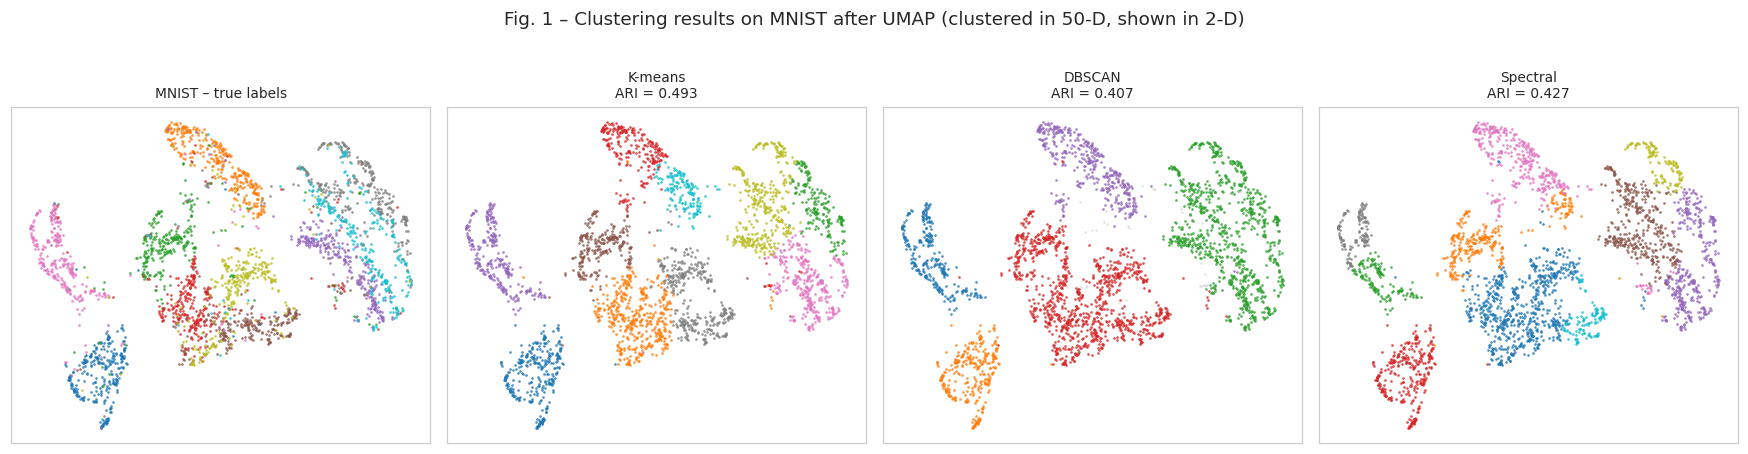

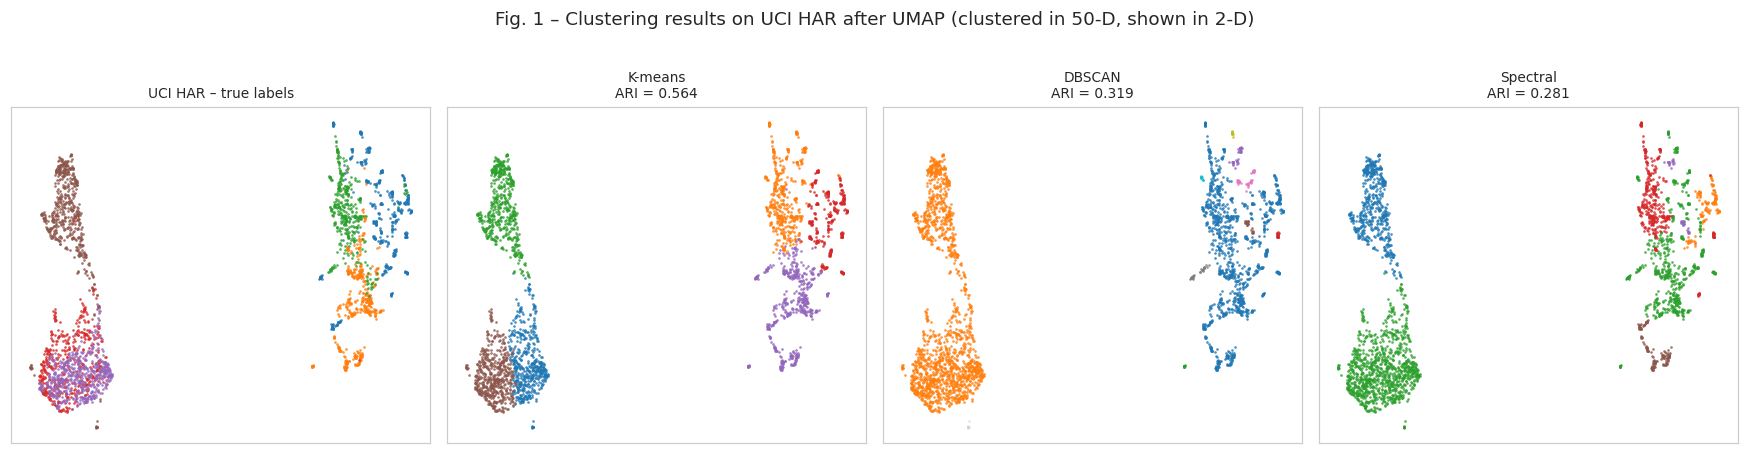

In [17]:
for name, d in DATASETS.items():
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    plot_labels(axes[0], d['vis2d'], d['y'], f'{name} – true labels')
    for ax, algo in zip(axes[1:], ALGOS):
        lab, _, _ = run_algorithm(algo, d['reps']['UMAP'], d['k'], EPS[(name, 'UMAP')], SEED)
        plot_labels(ax, d['vis2d'], lab, f"{algo}\nARI = {adjusted_rand_score(d['y'], lab):.3f}")
    plt.suptitle(f'Fig. 1 – Clustering results on {name} after UMAP (clustered in {DR_DIM}-D, shown in 2-D)', y=1.02)
    plt.tight_layout(); save_fig(fig, f"fig1_clusters_{name.replace(' ', '_')}"); plt.show()

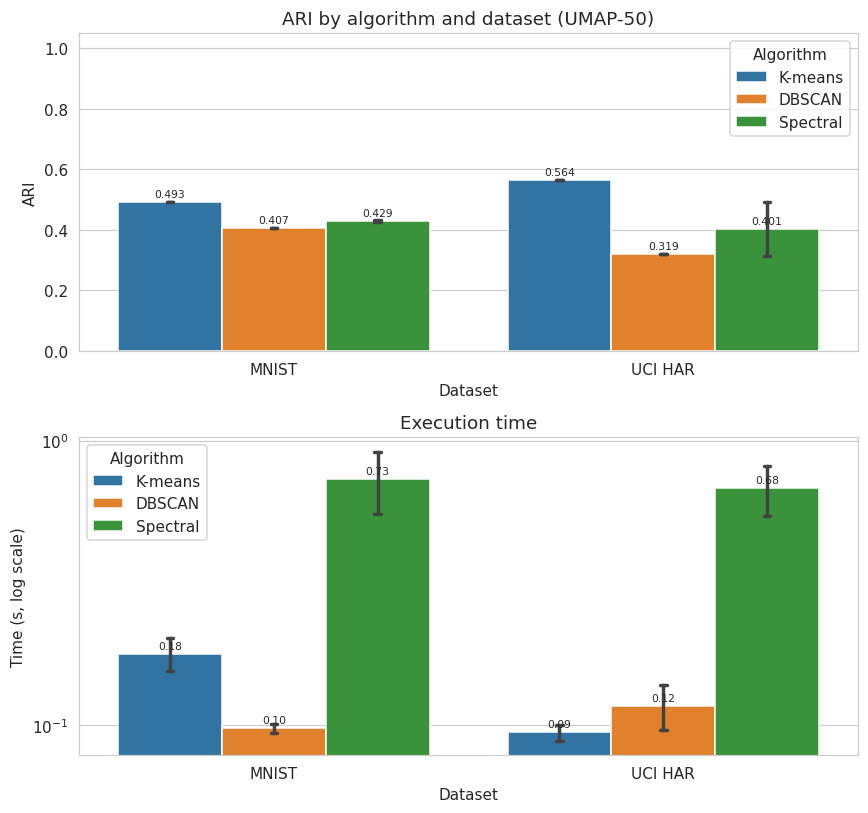

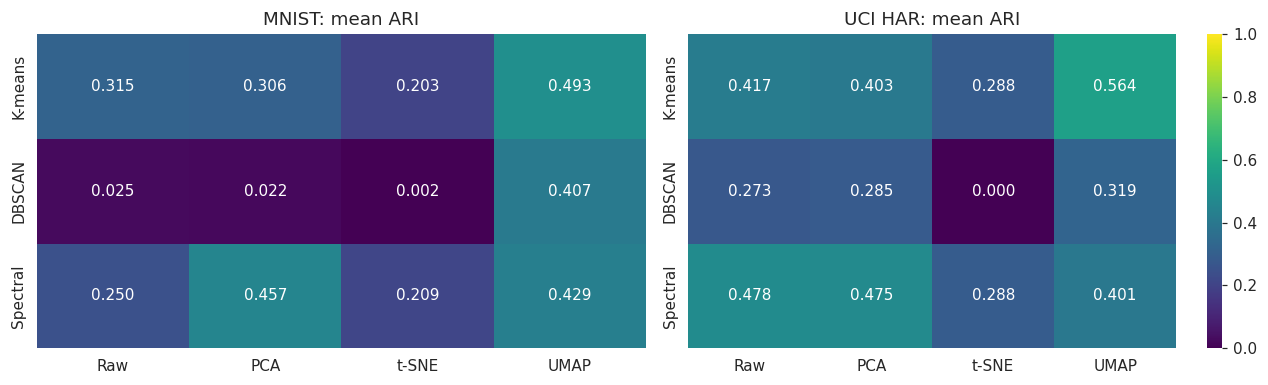

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7.5))
sns.barplot(data=umap_df, x='Dataset', y='ARI', hue='Algorithm', hue_order=ALGOS,
            palette=PALETTE, errorbar='sd', capsize=0.05, ax=axes[0])
for c in axes[0].containers: axes[0].bar_label(c, fmt='%.3f', fontsize=7, padding=2)
axes[0].set_ylim(0, 1.05); axes[0].set_title('ARI by algorithm and dataset (UMAP-50)')
sns.barplot(data=umap_df, x='Dataset', y='Time_wall', hue='Algorithm', hue_order=ALGOS,
            palette=PALETTE, errorbar='sd', capsize=0.05, ax=axes[1])
for c in axes[1].containers: axes[1].bar_label(c, fmt='%.2f', fontsize=7, padding=2)
axes[1].set_yscale('log'); axes[1].set_ylabel('Time (s, log scale)'); axes[1].set_title('Execution time')
plt.tight_layout(); save_fig(fig, 'fig2_ari_and_time'); plt.show()

fig, axes = plt.subplots(1, len(DATASETS), figsize=(12, 3.6))
for ax, name in zip(axes, DATASETS):
    piv = (df_results[df_results.Dataset == name].groupby(['Algorithm', 'Representation'])['ARI']
           .mean().unstack().reindex(index=ALGOS, columns=REPS))
    sns.heatmap(piv, annot=True, fmt='.3f', cmap='viridis', vmin=0, vmax=1, ax=ax, cbar=ax is axes[-1])
    ax.set_title(f'{name}: mean ARI'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); save_fig(fig, 'fig2b_ari_heatmap'); plt.show()

In [19]:
STAB_DATASETS = ['MNIST']
STAB_REPS     = ['PCA', 't-SNE', 'UMAP']

def pairwise_consistency(label_list, max_pairs=1000, seed=0):
    pairs = list(combinations(range(len(label_list)), 2))
    if len(pairs) > max_pairs:
        idx = np.random.default_rng(seed).choice(len(pairs), max_pairs, replace=False)
        pairs = [pairs[i] for i in idx]
    return float(np.mean([adjusted_rand_score(label_list[i], label_list[j]) for i, j in pairs]))

stab_rows, stab_summary = [], []
t0 = time.perf_counter()
for name in STAB_DATASETS:
    d = DATASETS[name]
    for rep in STAB_REPS:
        X = d['reps'][rep]
        for algo in ALGOS:
            labelings, aris = [], []
            for r in range(N_STABILITY):
                lab, _, _ = run_algorithm(algo, X, d['k'], eps=EPS[(name, rep)], seed=1000 + r)
                ari = adjusted_rand_score(d['y'], lab)
                labelings.append(lab); aris.append(ari)
                stab_rows.append({'Dataset': name, 'Representation': rep, 'Algorithm': algo, 'Run': r, 'ARI': ari})
            mean, std = np.mean(aris), np.std(aris)
            stab_summary.append({'Dataset': name, 'Algorithm': algo, 'Dimensionality Reduction': rep,
                                 'ARI Mean': round(mean, 3), 'ARI StdDev': round(std, 3),
                                 'Stability Score (1-CV)': round(1 - std / mean, 3) if mean > 0 else np.nan,
                                 'Pairwise consistency (ARI)': round(pairwise_consistency(labelings), 3)})
            print(f"{name} | {rep:6s} | {algo:9s} | ARI {mean:.3f} ± {std:.3f} | "
                  f"{(time.perf_counter() - t0) / 60:.1f} min")

df_stab = pd.DataFrame(stab_rows)
table3 = pd.DataFrame(stab_summary).sort_values(['Dataset', 'Algorithm', 'Dimensionality Reduction'],
                                                key=lambda s: s.map({**{a: i for i, a in enumerate(ALGOS)},
                                                                     **{r: i for i, r in enumerate(STAB_REPS)}}).fillna(0))
print("\nTABLE III – Clustering stability analysis")
display(table3)
save_table(table3, 'table3_stability')
df_stab.to_csv(os.path.join(TAB_DIR, 'stability_all_runs.csv'), index=False)

MNIST | PCA    | K-means   | ARI 0.309 ± 0.013 | 0.4 min
MNIST | PCA    | DBSCAN    | ARI 0.022 ± 0.000 | 1.1 min
MNIST | PCA    | Spectral  | ARI 0.456 ± 0.001 | 2.9 min
MNIST | t-SNE  | K-means   | ARI 0.203 ± 0.005 | 3.3 min
MNIST | t-SNE  | DBSCAN    | ARI 0.002 ± 0.000 | 4.0 min
MNIST | t-SNE  | Spectral  | ARI 0.209 ± 0.000 | 6.1 min
MNIST | UMAP   | K-means   | ARI 0.493 ± 0.002 | 6.3 min
MNIST | UMAP   | DBSCAN    | ARI 0.407 ± 0.000 | 6.5 min
MNIST | UMAP   | Spectral  | ARI 0.427 ± 0.004 | 7.8 min

TABLE III – Clustering stability analysis


,Dataset,Algorithm,Dimensionality Reduction,ARI Mean,ARI StdDev,Stability Score (1-CV),Pairwise consistency (ARI)
0,MNIST,K-means,PCA,0.309,0.013,0.959,0.719
3,MNIST,K-means,t-SNE,0.203,0.005,0.975,0.773
6,MNIST,K-means,UMAP,0.493,0.002,0.996,0.986
1,MNIST,DBSCAN,PCA,0.022,0.000,1.000,1.000
4,MNIST,DBSCAN,t-SNE,0.002,0.000,1.000,1.000
7,MNIST,DBSCAN,UMAP,0.407,0.000,1.000,1.000
2,MNIST,Spectral,PCA,0.456,0.001,0.998,0.996
5,MNIST,Spectral,t-SNE,0.209,0.000,0.998,0.995
8,MNIST,Spectral,UMAP,0.427,0.004,0.990,0.994


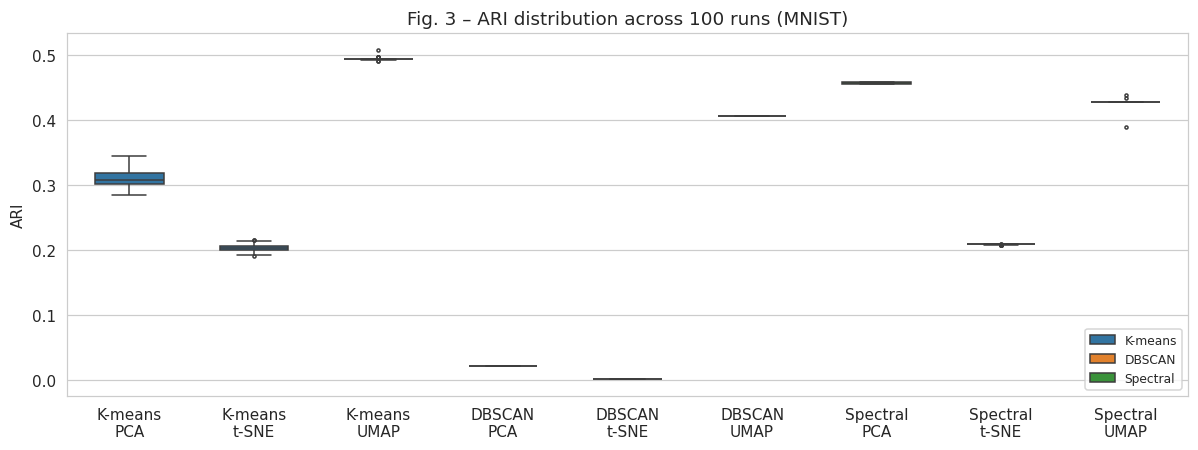

In [20]:
for name in STAB_DATASETS:
    sub = df_stab[df_stab.Dataset == name].copy()
    sub['Configuration'] = sub.Algorithm + '\n' + sub.Representation
    order = [f'{a}\n{r}' for a in ALGOS for r in STAB_REPS]
    fig, ax = plt.subplots(figsize=(11, 4.2))
    sns.boxplot(data=sub, x='Configuration', y='ARI', hue='Algorithm', order=order,
                palette=PALETTE, dodge=False, width=0.55, fliersize=2, ax=ax)
    ax.set_title(f'Fig. 3 – ARI distribution across {N_STABILITY} runs ({name})')
    ax.set_xlabel(''); ax.legend(loc='lower right', fontsize=8)
    plt.tight_layout(); save_fig(fig, f"fig3_stability_{name.replace(' ', '_')}"); plt.show()

In [21]:
# ---------- Cell 19A (NEW): why is Spectral unstable on UCI HAR + UMAP? ----------
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import kneighbors_graph

print("Connected components of the 10-NN affinity graph (1 = fully connected):")
comp_rows = []
for name, d in DATASETS.items():
    for rep in REPS:
        G = kneighbors_graph(d['reps'][rep], n_neighbors=SPEC_NEIGHBORS, include_self=True)
        G = 0.5 * (G + G.T)
        nc = connected_components(G, directed=False)[0]
        comp_rows.append({'Dataset': name, 'Representation': rep, 'Components': nc})
        print(f"  {name:8s} {rep:6s} components = {nc}")
comp_df = pd.DataFrame(comp_rows)
display(comp_df)
save_table(comp_df, 'tableS2a_spectral_graph_components')

# Sensitivity of Spectral (UMAP-50) to the neighbourhood size
sens = []
for name, d in DATASETS.items():
    X = d['reps']['UMAP']
    for nn in [10, 20, 30]:
        aris = []
        for r in range(N_RUNS):
            lab = SpectralClustering(n_clusters=d['k'], affinity='nearest_neighbors',
                                     n_neighbors=nn, assign_labels='kmeans',
                                     random_state=SEED + r, n_jobs=-1).fit_predict(X)
            aris.append(adjusted_rand_score(d['y'], lab))
        sens.append({'Dataset': name, 'n_neighbors': nn, 'ARI (UMAP-50)': pm(aris)})
sens_df = pd.DataFrame(sens)
display(sens_df)
save_table(sens_df, 'tableS2b_spectral_sensitivity')

Connected components of the 10-NN affinity graph (1 = fully connected):
  MNIST    Raw    components = 1
  MNIST    PCA    components = 1
  MNIST    t-SNE  components = 1
  MNIST    UMAP   components = 3
  UCI HAR  Raw    components = 1
  UCI HAR  PCA    components = 1
  UCI HAR  t-SNE  components = 1
  UCI HAR  UMAP   components = 16


,Dataset,Representation,Components
0,MNIST,Raw,1
1,MNIST,PCA,1
2,MNIST,t-SNE,1
3,MNIST,UMAP,3
4,UCI HAR,Raw,1
5,UCI HAR,PCA,1
6,UCI HAR,t-SNE,1
7,UCI HAR,UMAP,16


,Dataset,n_neighbors,ARI (UMAP-50)
0,MNIST,10,0.429 ± 0.004
1,MNIST,20,0.476 ± 0.005
2,MNIST,30,0.480 ± 0.006
3,UCI HAR,10,0.401 ± 0.085
4,UCI HAR,20,0.497 ± 0.096
5,UCI HAR,30,0.540 ± 0.000


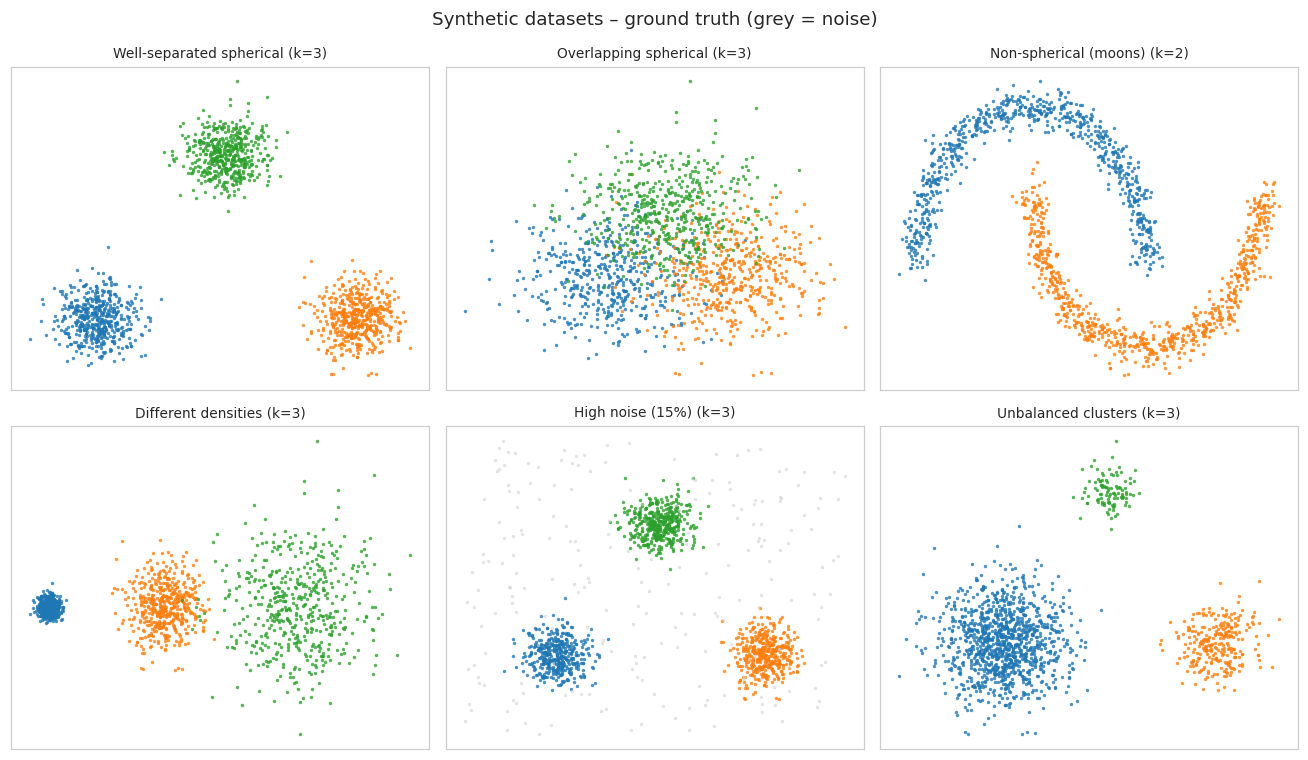

In [22]:
def make_synthetic(n=1500, seed=SEED):
    rng = np.random.default_rng(seed)
    data = {}
    X, y = make_blobs(n_samples=n, centers=[[-5, 0], [5, 0], [0, 7]], cluster_std=0.8, random_state=seed)
    data['Well-separated spherical'] = (X, y, 3)
    X, y = make_blobs(n_samples=n, centers=[[-2, 0], [2, 0], [0, 3]], cluster_std=1.5, random_state=seed)
    data['Overlapping spherical'] = (X, y, 3)
    X, y = make_moons(n_samples=n, noise=0.06, random_state=seed)
    data['Non-spherical (moons)'] = (X, y, 2)
    X, y = make_blobs(n_samples=[n // 3, n // 3, n - 2 * (n // 3)], centers=[[-6, 0], [0, 0], [7, 0]],
                      cluster_std=[0.3, 1.0, 2.0], random_state=seed)
    data['Different densities'] = (X, y, 3)
    n_noise = int(0.15 * n)
    Xc, yc = make_blobs(n_samples=n - n_noise, centers=[[-5, 0], [5, 0], [0, 7]], cluster_std=0.8, random_state=seed)
    Xn = rng.uniform(Xc.min(0) - 2, Xc.max(0) + 2, size=(n_noise, 2))
    data['High noise (15%)'] = (np.vstack([Xc, Xn]), np.concatenate([yc, -np.ones(n_noise, int)]), 3)
    sizes = [int(.75 * n), int(.18 * n)]; sizes.append(n - sum(sizes))
    X, y = make_blobs(n_samples=sizes, centers=[[-4, 0], [4, 0], [0, 6]], cluster_std=[1.2, 0.8, 0.5], random_state=seed)
    data['Unbalanced clusters'] = (X, y, 3)
    # standardize, as for the real data
    return {k: (StandardScaler().fit_transform(X), y, kk) for k, (X, y, kk) in data.items()}

SYNTH = make_synthetic()
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (nm, (X, y, k)) in zip(axes.ravel(), SYNTH.items()):
    plot_labels(ax, X, y, f'{nm} (k={k})', s=5)
plt.suptitle('Synthetic datasets – ground truth (grey = noise)'); plt.tight_layout(); plt.show()

Well-separated spherical   | K-means 1.000 | DBSCAN 0.841 | Spectral 1.000 | eps=0.087 (silhouette) | best: K-means
Overlapping spherical      | K-means 0.536 | DBSCAN 0.000 | Spectral 0.531 | eps=0.270 (silhouette) | best: K-means
Non-spherical (moons)      | K-means 0.484 | DBSCAN 0.879 | Spectral 1.000 | eps=0.096 (silhouette) | best: Spectral
Different densities        | K-means 0.366 | DBSCAN 0.828 | Spectral 0.501 | eps=0.188 (silhouette) | best: DBSCAN
High noise (15%)           | K-means 0.764 | DBSCAN 0.853 | Spectral 0.764 | eps=0.098 (silhouette) | best: DBSCAN
Unbalanced clusters        | K-means 0.991 | DBSCAN 0.825 | Spectral 1.000 | eps=0.155 (silhouette) | best: Spectral

TABLE IV – Algorithm performance on different data characteristics (ARI)


,Data Characteristic,eps,eps rule,K-means,DBSCAN,Spectral,Best algorithm
0,Well-separated spherical,0.087,silhouette,1.000,0.841,1.000,K-means
1,Overlapping spherical,0.270,silhouette,0.536,0.000,0.531,K-means
2,Non-spherical (moons),0.096,silhouette,0.484,0.879,1.000,Spectral
3,Different densities,0.188,silhouette,0.366,0.828,0.501,DBSCAN
4,High noise (15%),0.098,silhouette,0.764,0.853,0.764,DBSCAN
5,Unbalanced clusters,0.155,silhouette,0.991,0.825,1.000,Spectral


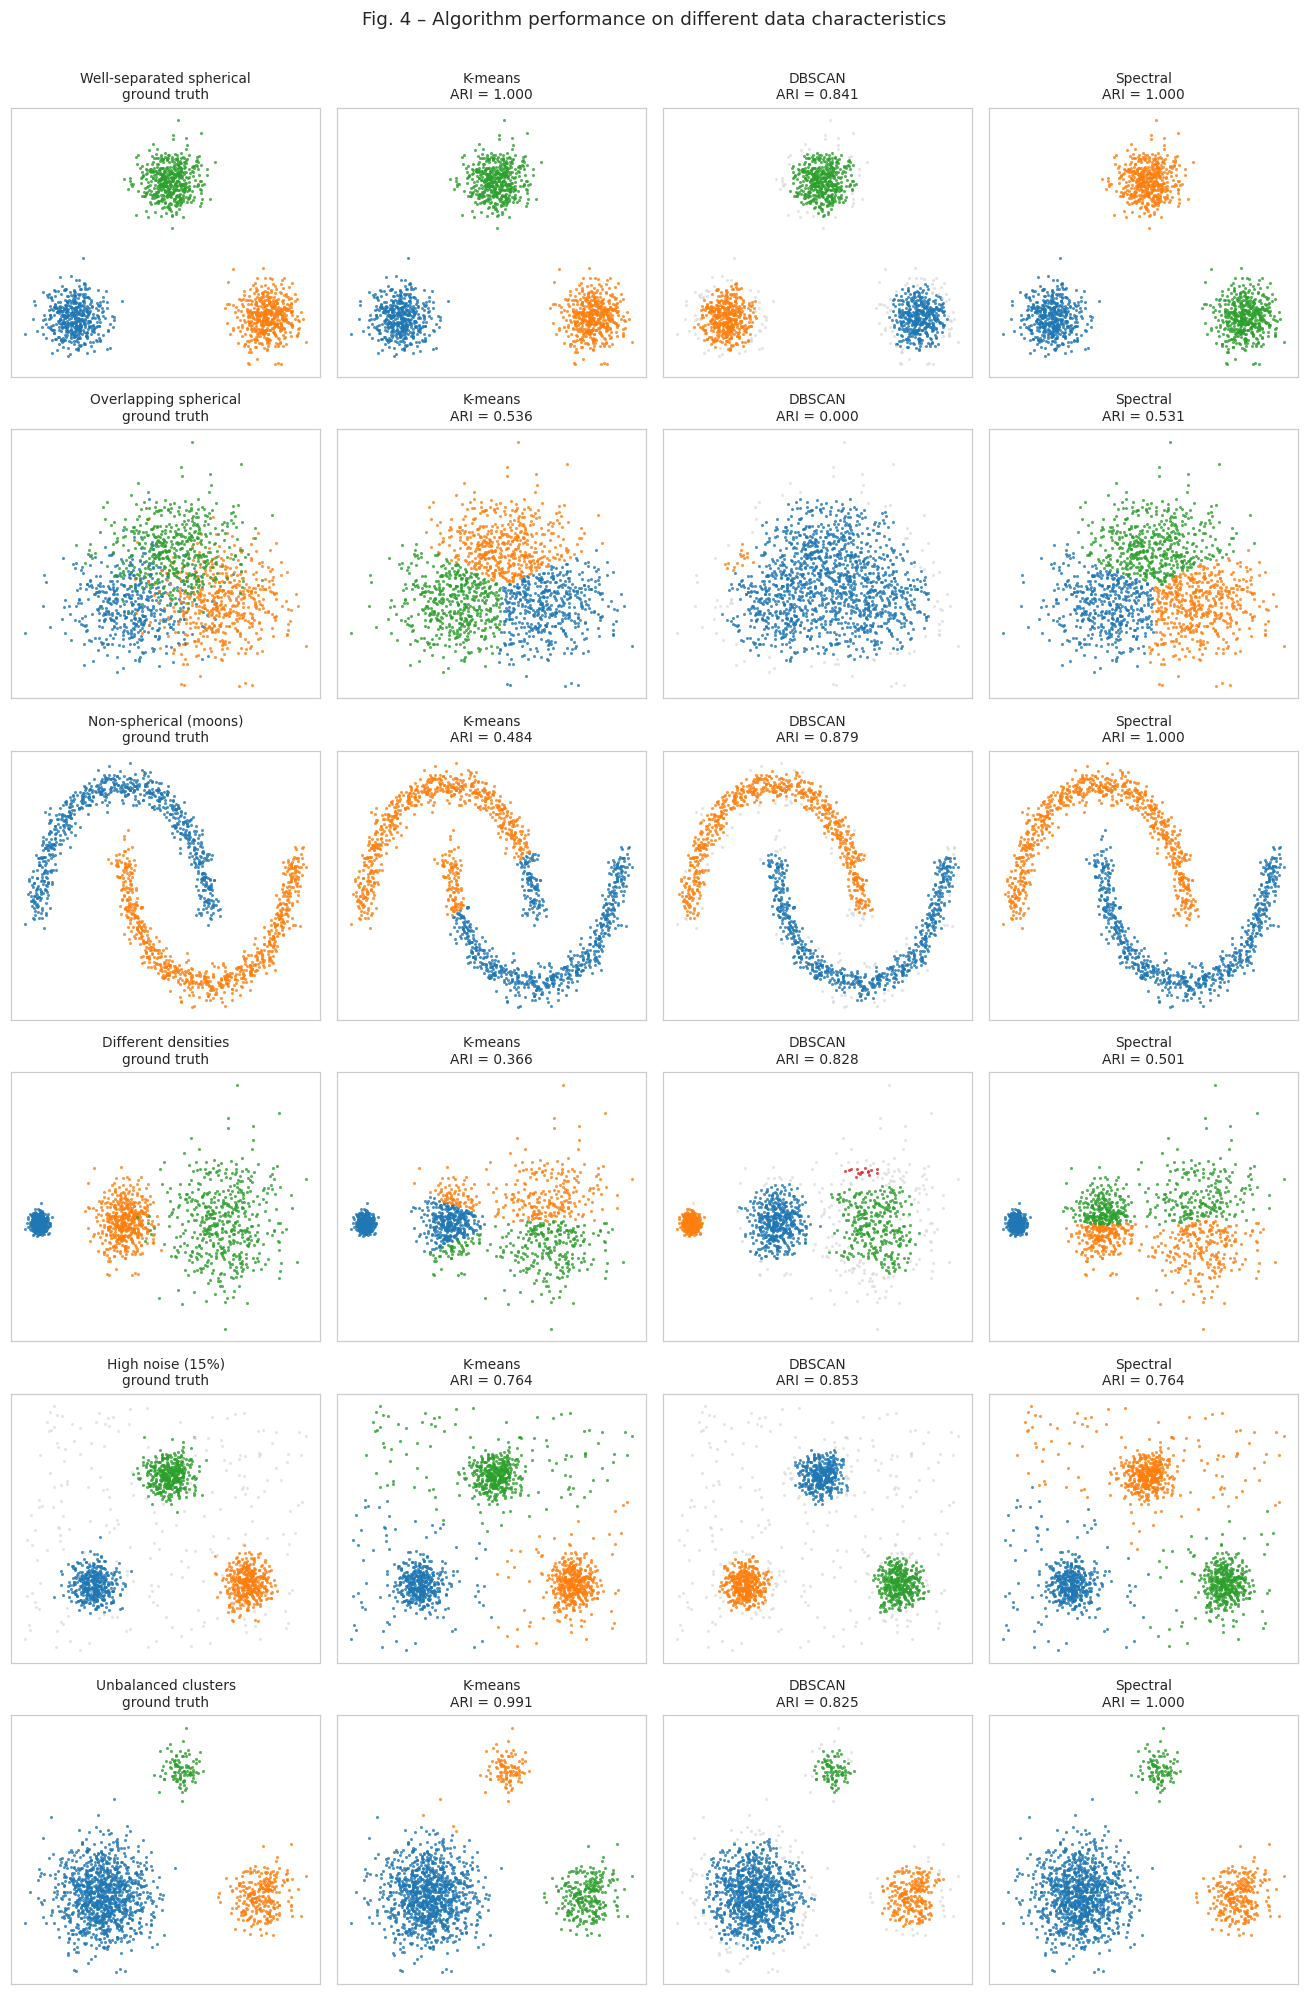

In [23]:
# ---------- Cell 21 (REPLACES old Cell 21): synthetic data, label-free eps ----------
synth_rows, synth_labels = [], {}
for nm, (X, y, k) in SYNTH.items():
    eps, sw, flag = select_eps(X, y, k)     # y only logged for the oracle, not used to pick eps
    row = {'Data Characteristic': nm, 'eps': round(eps, 3), 'eps rule': flag}
    for algo in ALGOS:
        runs = 1 if algo == 'DBSCAN' else N_RUNS
        aris = []
        for r in range(runs):
            lab, _, _ = run_algorithm(algo, X, k, eps=eps, seed=SEED + r)
            aris.append(adjusted_rand_score(y, lab))
            if r == 0:
                synth_labels[(nm, algo)] = lab
        row[algo] = round(np.mean(aris), 3)
    row['Best algorithm'] = max(ALGOS, key=lambda a: row[a])
    synth_rows.append(row)
    print(f"{nm:26s} | " + " | ".join(f"{a} {row[a]:.3f}" for a in ALGOS) +
          f" | eps={eps:.3f} ({flag}) | best: {row['Best algorithm']}")

table4 = pd.DataFrame(synth_rows)
print("\nTABLE IV – Algorithm performance on different data characteristics (ARI)")
display(table4)
save_table(table4, 'table4_synthetic')

fig, axes = plt.subplots(len(SYNTH), 4, figsize=(12, 3 * len(SYNTH)))
for i, (nm, (X, y, k)) in enumerate(SYNTH.items()):
    plot_labels(axes[i, 0], X, y, f'{nm}\nground truth', s=4)
    for j, algo in enumerate(ALGOS, start=1):
        plot_labels(axes[i, j], X, synth_labels[(nm, algo)],
                    f"{algo}\nARI = {table4.loc[i, algo]:.3f}", s=4)
plt.suptitle('Fig. 4 – Algorithm performance on different data characteristics', y=1.005)
plt.tight_layout(); save_fig(fig, 'fig4_synthetic'); plt.show()

In [24]:
# ---------- Cell 21A (NEW): is poor t-SNE performance due to the 50-D kernel? ----------
from sklearn.manifold import TSNE

rows = []
for name, d in DATASETS.items():
    Z2 = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto',
              random_state=SEED).fit_transform(d['X_std'])
    eps, _, flag = select_eps(Z2, d['y'], d['k'])
    for algo in ALGOS:
        runs = 1 if algo == 'DBSCAN' else N_RUNS
        aris = [adjusted_rand_score(d['y'], run_algorithm(algo, Z2, d['k'], eps=eps, seed=SEED + r)[0])
                for r in range(runs)]
        rows.append({'Dataset': name, 'Algorithm': algo, 'eps rule': flag,
                     'ARI (t-SNE 2-D)': pm(aris)})
tsne2 = pd.DataFrame(rows)
display(tsne2)
save_table(tsne2, 'tableS3_tsne2d')

,Dataset,Algorithm,eps rule,ARI (t-SNE 2-D)
0,MNIST,K-means,FALLBACK-closest-k,0.414 ± 0.002
1,MNIST,DBSCAN,FALLBACK-closest-k,0.148 ± 0.000
2,MNIST,Spectral,FALLBACK-closest-k,0.366 ± 0.001
3,UCI HAR,K-means,FALLBACK-closest-k,0.566 ± 0.000
4,UCI HAR,DBSCAN,FALLBACK-closest-k,0.325 ± 0.000
5,UCI HAR,Spectral,FALLBACK-closest-k,0.299 ± 0.127


In [25]:
ctrl = []
for name, d in DATASETS.items():
    for algo in ['K-means', 'Spectral']:
        aris = [adjusted_rand_score(d['y'], run_algorithm(algo, d['vis2d'], d['k'], seed=SEED + r)[0])
                for r in range(N_RUNS)]
        ctrl.append({'Dataset': name, 'Algorithm': algo,
                     'Space': 'UMAP-2D (control)', 'ARI': pm(aris)})
ctrl = pd.DataFrame(ctrl)
display(ctrl)
save_table(ctrl, 'tableS4_umap2d_control')

,Dataset,Algorithm,Space,ARI
0,MNIST,K-means,UMAP-2D (control),0.506 ± 0.006
1,MNIST,Spectral,UMAP-2D (control),0.399 ± 0.000
2,UCI HAR,K-means,UMAP-2D (control),0.568 ± 0.000
3,UCI HAR,Spectral,UMAP-2D (control),0.412 ± 0.101


In [26]:
print("=" * 90); print("KEY FINDINGS (generated from YOUR results)"); print("=" * 90)
ari_mean = df_results.groupby(['Dataset', 'Algorithm', 'Representation'])['ARI'].mean()

print("\n[1] Impact of dimensionality reduction (mean ARI)")
for name in DATASETS:
    for algo in ALGOS:
        s = ari_mean.loc[(name, algo)].reindex(REPS)
        ratio = s['UMAP'] / s['Raw'] if s['Raw'] > 1e-6 else float('inf')
        print(f"  {name:8s} {algo:9s}: best = {s.idxmax():6s} ({s.max():.3f}) | Raw {s['Raw']:.3f} → "
              f"PCA {s['PCA']:.3f} → t-SNE {s['t-SNE']:.3f} → UMAP {s['UMAP']:.3f} (UMAP/Raw = {ratio:.2f}×)")

print("\n[2] Algorithm comparison after UMAP")
m = umap_df.groupby(['Dataset', 'Algorithm'])[['ARI', 'NMI', 'Silhouette', 'Davies-Bouldin', 'Time_wall']].mean()
for name in DATASETS:
    mm = m.loc[name]
    print(f"  {name}: ARI → {mm.ARI.idxmax()} ({mm.ARI.max():.3f}); NMI → {mm.NMI.idxmax()}; "
          f"Silhouette → {mm.Silhouette.idxmax()}; Davies-Bouldin → {mm['Davies-Bouldin'].idxmin()}")
    print(f"     Time: Spectral is {mm.Time_wall['Spectral'] / mm.Time_wall['K-means']:.1f}× and "
          f"DBSCAN {mm.Time_wall['DBSCAN'] / mm.Time_wall['K-means']:.1f}× the K-means time")
    if mm.Silhouette.idxmax() != mm.ARI.idxmax():
        print(f"     → Metric divergence: best internal score ({mm.Silhouette.idxmax()}) ≠ best ARI ({mm.ARI.idxmax()})")

print("\n[3] Stability")
t3 = pd.DataFrame(stab_summary)
nz = t3[t3['ARI StdDev'] > 0]
if len(nz):
    print(f"  Most variable : {nz.loc[nz['ARI StdDev'].idxmax(), ['Algorithm', 'Dimensionality Reduction']].tolist()}")
best = t3.loc[t3['ARI Mean'].idxmax()]
print(f"  Highest ARI   : {best.Algorithm} + {best['Dimensionality Reduction']} "
      f"(ARI {best['ARI Mean']:.3f}, std {best['ARI StdDev']:.3f})")

print("\n[4] Synthetic data – winner per characteristic")
for _, r in table4.iterrows():
    print(f"  {r['Data Characteristic']:26s}: {r['Best algorithm']}")

KEY FINDINGS (generated from YOUR results)

[1] Impact of dimensionality reduction (mean ARI)
  MNIST    K-means  : best = UMAP   (0.493) | Raw 0.315 → PCA 0.306 → t-SNE 0.203 → UMAP 0.493 (UMAP/Raw = 1.57×)
  MNIST    DBSCAN   : best = UMAP   (0.407) | Raw 0.025 → PCA 0.022 → t-SNE 0.002 → UMAP 0.407 (UMAP/Raw = 16.37×)
  MNIST    Spectral : best = PCA    (0.457) | Raw 0.250 → PCA 0.457 → t-SNE 0.209 → UMAP 0.429 (UMAP/Raw = 1.72×)
  UCI HAR  K-means  : best = UMAP   (0.564) | Raw 0.417 → PCA 0.403 → t-SNE 0.288 → UMAP 0.564 (UMAP/Raw = 1.35×)
  UCI HAR  DBSCAN   : best = UMAP   (0.319) | Raw 0.273 → PCA 0.285 → t-SNE 0.000 → UMAP 0.319 (UMAP/Raw = 1.17×)
  UCI HAR  Spectral : best = Raw    (0.478) | Raw 0.478 → PCA 0.475 → t-SNE 0.288 → UMAP 0.401 (UMAP/Raw = 0.84×)

[2] Algorithm comparison after UMAP
  MNIST: ARI → K-means (0.493); NMI → K-means; Silhouette → DBSCAN; Davies-Bouldin → K-means
     Time: Spectral is 4.1× and DBSCAN 0.5× the K-means time
     → Metric divergence: best

In [27]:
archive = shutil.make_archive('/content/clustering_replication_results', 'zip', OUT_DIR)
print("Created:", archive)
for root, _, files in os.walk(OUT_DIR):
    if 'cache' in root: continue
    for f in sorted(files):
        print("  ", os.path.relpath(os.path.join(root, f), OUT_DIR))
from google.colab import files
files.download(archive)

Created: /content/clustering_replication_results.zip
   figures/fig0_class_distribution.pdf
   figures/fig0_class_distribution.png
   figures/fig1_clusters_MNIST.pdf
   figures/fig1_clusters_MNIST.png
   figures/fig1_clusters_UCI_HAR.pdf
   figures/fig1_clusters_UCI_HAR.png
   figures/fig2_ari_and_time.pdf
   figures/fig2_ari_and_time.png
   figures/fig2b_ari_heatmap.pdf
   figures/fig2b_ari_heatmap.png
   figures/fig3_stability_MNIST.pdf
   figures/fig3_stability_MNIST.png
   figures/fig4_synthetic.pdf
   figures/fig4_synthetic.png
   figures/figS1_kdistance.pdf
   figures/figS1_kdistance.png
   figures/figS2_dbscan_sweep.pdf
   figures/figS2_dbscan_sweep.png
   tables/all_runs_results.csv
   tables/dataset_summary.csv
   tables/dataset_summary.tex
   tables/dbscan_eps_sweep_all.csv
   tables/stability_all_runs.csv
   tables/table1_ari_by_dr.csv
   tables/table1_ari_by_dr.tex
   tables/table2_umap_comparison.csv
   tables/table2_umap_comparison.tex
   tables/table3_stability.csv
   ta

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>